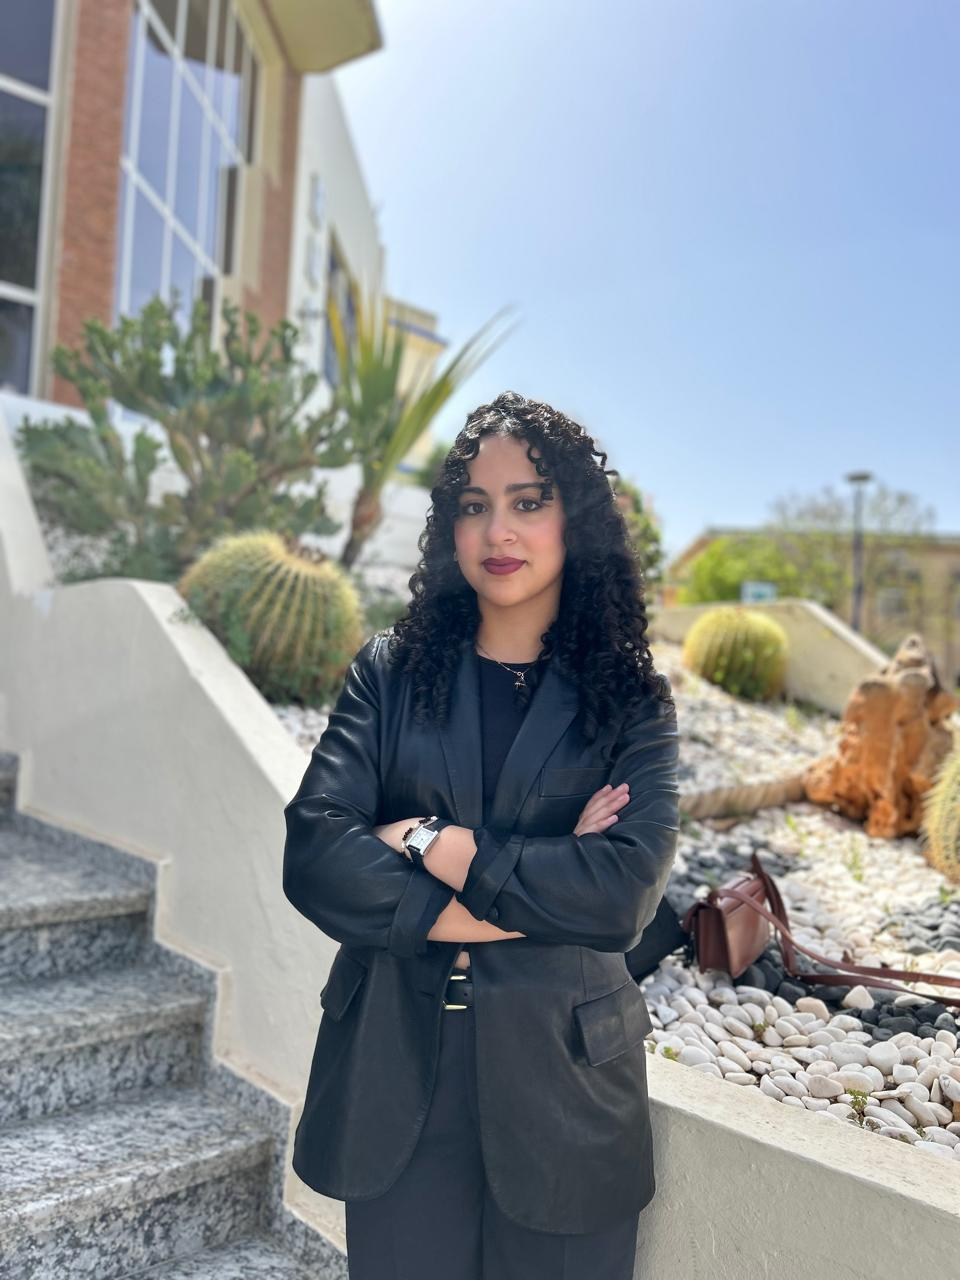

[![Ouvrir dans Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://github.com/NINIETTE/23009287-MERIEM-NINIA-FIN)

In [ ]:
!pip -q install -U scikit-learn xgboost umap-learn gymnasium

In [ ]:
# Validation de l'installation des dépendances nécessaires
import sys
!{sys.executable} -m pip install -q -U scikit-learn xgboost umap-learn gymnasium

In [ ]:
# Sources réelles intégrées à scikit-learn : trois problèmes différents
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes, load_breast_cancer, load_wine
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, f1_score, roc_auc_score, silhouette_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
GRAINE = 42

jeu_regression = load_diabetes()
X_reg, y_reg = jeu_regression.data, jeu_regression.target
jeu_classification = load_breast_cancer()
X_cls, y_cls = jeu_classification.data, jeu_classification.target
jeu_non_supervise = load_wine()
X_clu = StandardScaler().fit_transform(jeu_non_supervise.data)  # Exploration sans cible

Xr_ent, Xr_test, yr_ent, yr_test = train_test_split(X_reg, y_reg, test_size=.25, random_state=GRAINE)
Xc_ent, Xc_test, yc_ent, yc_test = train_test_split(X_cls, y_cls, test_size=.25, stratify=y_cls, random_state=GRAINE)
print('Diabetes:', X_reg.shape, '| Breast Cancer:', X_cls.shape, '| Wine:', X_clu.shape)
print('Ces données sont réelles ; les étiquettes du vin ne sont pas employées dans le clustering.')

Diabetes: (442, 10) | Breast Cancer: (569, 30) | Wine: (178, 13)
Ces données sont réelles ; les étiquettes du vin ne sont pas employées dans le clustering.


## 1. Régression linéaire

**Variante C — question spécifique :** Quel diagnostic du résidu indique une mauvaise spécification linéaire ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
from sklearn.linear_model import LinearRegression
modele = LinearRegression().fit(Xr_ent, yr_ent)
predictions = modele.predict(Xr_test)
print('MAE régression linéaire :', round(mean_absolute_error(yr_test, predictions), 2))
print('R² :', round(r2_score(yr_test, predictions), 3))

MAE régression linéaire : 41.55
R² : 0.485


## 2. Ridge

**Variante C — question spécifique :** Comment évoluent les coefficients quand alpha augmente ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
from sklearn.linear_model import Ridge
modele = make_pipeline(StandardScaler(), Ridge(alpha=12.0)).fit(Xr_ent, yr_ent)
print('MAE Ridge :', round(mean_absolute_error(yr_test, modele.predict(Xr_test)), 2))

MAE Ridge : 41.46


## 3. Lasso

**Variante C — question spécifique :** Combien de variables sont annulées pour trois valeurs d’alpha ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
from sklearn.linear_model import Lasso
modele = make_pipeline(StandardScaler(), Lasso(alpha=2.0, max_iter=15000)).fit(Xr_ent, yr_ent)
print('Nombre de coefficients non nuls :', np.count_nonzero(modele[-1].coef_))
print('MAE Lasso :', round(mean_absolute_error(yr_test, modele.predict(Xr_test)), 2))

Nombre de coefficients non nuls : 8
MAE Lasso : 41.37


## 4. Régression polynomiale

**Variante C — question spécifique :** Le degré 2 améliore-t-il le test ou seulement l’entraînement ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge
modele = make_pipeline(StandardScaler(), PolynomialFeatures(degree=2, include_bias=False), Ridge(alpha=100.)).fit(Xr_ent, yr_ent)
print('R² polynomial :', round(r2_score(yr_test, modele.predict(Xr_test)), 3))

R² polynomial : 0.501


## 5. Arbre de régression

**Variante C — question spécifique :** Quel effet de max_depth sur le biais et la variance ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
from sklearn.tree import DecisionTreeRegressor
modele = DecisionTreeRegressor(max_depth=3, min_samples_leaf=8, random_state=GRAINE).fit(Xr_ent, yr_ent)
print('MAE arbre :', round(mean_absolute_error(yr_test, modele.predict(Xr_test)), 2))

MAE arbre : 44.57


## 6. Forêt aléatoire — régression

**Variante C — question spécifique :** La forêt réduit-elle la variance par rapport à l’arbre ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
from sklearn.ensemble import RandomForestRegressor
modele = RandomForestRegressor(n_estimators=60, max_depth=6, n_jobs=-1, random_state=GRAINE).fit(Xr_ent, yr_ent)
print('MAE forêt :', round(mean_absolute_error(yr_test, modele.predict(Xr_test)), 2))

MAE forêt : 43.11


## 7. Gradient Boosting — régression

**Variante C — question spécifique :** Que change max_iter sur le coût et le risque de surajustement ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
from sklearn.ensemble import HistGradientBoostingRegressor
modele = HistGradientBoostingRegressor(max_iter=100, max_leaf_nodes=9, random_state=GRAINE).fit(Xr_ent, yr_ent)
print('MAE boosting :', round(mean_absolute_error(yr_test, modele.predict(Xr_test)), 2))

MAE boosting : 44.18


## 8. Régression logistique

**Variante C — question spécifique :** Quel effet de C sur les probabilités et la frontière ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
from sklearn.linear_model import LogisticRegression
modele = make_pipeline(StandardScaler(), LogisticRegression(C=.5, max_iter=2000, random_state=GRAINE)).fit(Xc_ent, yc_ent)
print('F1 logistique :', round(f1_score(yc_test, modele.predict(Xc_test)), 3))

F1 logistique : 0.989


## 9. KNN

**Variante C — question spécifique :** Comparez k = 3, 7 et 15 ; quelle métrique varie ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
from sklearn.neighbors import KNeighborsClassifier
modele = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7, weights='distance')).fit(Xc_ent, yc_ent)
print('F1 KNN :', round(f1_score(yc_test, modele.predict(Xc_test)), 3))

F1 KNN : 0.984


## 10. Naive Bayes

**Variante C — question spécifique :** Dans quel cas l’hypothèse d’indépendance devient-elle critique ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
from sklearn.naive_bayes import GaussianNB
modele = GaussianNB(var_smoothing=1e-8).fit(Xc_ent, yc_ent)
print('F1 Naive Bayes :', round(f1_score(yc_test, modele.predict(Xc_test)), 3))

F1 Naive Bayes : 0.962


## 11. Arbre de décision

**Variante C — question spécifique :** Quelle variable guide la première séparation de l’arbre ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
from sklearn.tree import DecisionTreeClassifier
modele = DecisionTreeClassifier(max_depth=3, min_samples_leaf=6, random_state=GRAINE).fit(Xc_ent, yc_ent)
print('F1 arbre :', round(f1_score(yc_test, modele.predict(Xc_test)), 3))

F1 arbre : 0.956


## 12. Forêt aléatoire — classification

**Variante C — question spécifique :** Quel effet du nombre d’arbres sur la stabilité ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
from sklearn.ensemble import RandomForestClassifier
modele = RandomForestClassifier(n_estimators=70, max_features='log2', random_state=GRAINE, n_jobs=-1).fit(Xc_ent, yc_ent)
print('F1 forêt :', round(f1_score(yc_test, modele.predict(Xc_test)), 3))

F1 forêt : 0.967


## 13. SVM

**Variante C — question spécifique :** Comparez noyau linéaire et RBF, et justifiez le choix.

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
from sklearn.svm import SVC
modele = make_pipeline(StandardScaler(), SVC(kernel='linear', C=.2, random_state=GRAINE)).fit(Xc_ent, yc_ent)
print('F1 SVM linéaire :', round(f1_score(yc_test, modele.predict(Xc_test)), 3))

F1 SVM linéaire : 0.989


## 14. Gradient Boosting — classification

**Variante C — question spécifique :** Quel effet du nombre d’itérations sur le temps et F1 ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
from sklearn.ensemble import HistGradientBoostingClassifier
modele = HistGradientBoostingClassifier(max_iter=65, max_leaf_nodes=8, random_state=GRAINE).fit(Xc_ent, yc_ent)
print('F1 boosting :', round(f1_score(yc_test, modele.predict(Xc_test)), 3))

F1 boosting : 0.967


## 15. AdaBoost

**Variante C — question spécifique :** Que change learning_rate quand n_estimators reste fixe ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
from sklearn.ensemble import AdaBoostClassifier
modele = AdaBoostClassifier(n_estimators=50, learning_rate=.6, random_state=GRAINE).fit(Xc_ent, yc_ent)
print('F1 AdaBoost :', round(f1_score(yc_test, modele.predict(Xc_test)), 3))

F1 AdaBoost : 0.973


## 16. XGBoost

**Variante C — question spécifique :** Que change max_depth sur la capacité du modèle ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
from xgboost import XGBClassifier
modele = XGBClassifier(n_estimators=65, max_depth=2, learning_rate=.08, random_state=GRAINE, eval_metric='logloss', n_jobs=2).fit(Xc_ent, yc_ent)
print('F1 XGBoost :', round(f1_score(yc_test, modele.predict(Xc_test)), 3))

F1 XGBoost : 0.967


## 17. K-means

**Variante C — question spécifique :** Évaluez k = 2, 3, 4 avec silhouette et inertie.

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
from sklearn.cluster import KMeans
modele = KMeans(n_clusters=3, n_init=15, random_state=GRAINE).fit(X_clu)
print('Inertie K-means :', round(modele.inertia_, 2))
print('Silhouette :', round(silhouette_score(X_clu, modele.labels_), 3))

Inertie K-means : 1277.93
Silhouette : 0.285


## 18. Classification hiérarchique

**Variante C — question spécifique :** Comparez complete et ward sur les mêmes données.

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
from sklearn.cluster import AgglomerativeClustering
etiquettes = AgglomerativeClustering(n_clusters=3, linkage='complete').fit_predict(X_clu)
print('Silhouette CHA (complete) :', round(silhouette_score(X_clu, etiquettes), 3))

Silhouette CHA (complete) : 0.204


## 19. DBSCAN

**Variante C — question spécifique :** Expliquez pourquoi eps modifie le nombre de points bruit.

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
from sklearn.cluster import DBSCAN
etiquettes = DBSCAN(eps=2.5, min_samples=4).fit_predict(X_clu)
print('Groupes détectés hors bruit :', len(set(etiquettes) - {-1}))
print('Points considérés comme bruit :', np.sum(etiquettes == -1))

Groupes détectés hors bruit : 1
Points considérés comme bruit : 23


## 20. Mélanges gaussiens

**Variante C — question spécifique :** Comparez covariance_type = full et diag.

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
from sklearn.mixture import GaussianMixture
modele = GaussianMixture(n_components=3, covariance_type='diag', random_state=GRAINE).fit(X_clu)
etiquettes = modele.predict(X_clu)
print('Poids du mélange :', np.round(modele.weights_, 3))
print('Silhouette :', round(silhouette_score(X_clu, etiquettes), 3) if len(set(etiquettes)) > 1 else 'non définie')

Poids du mélange : [0.352 0.287 0.361]
Silhouette : 0.281


## 21. ACP

**Variante C — question spécifique :** Combien de composantes faut-il pour 80 % de variance ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


Variance expliquée par composante : [0.362 0.192 0.111]


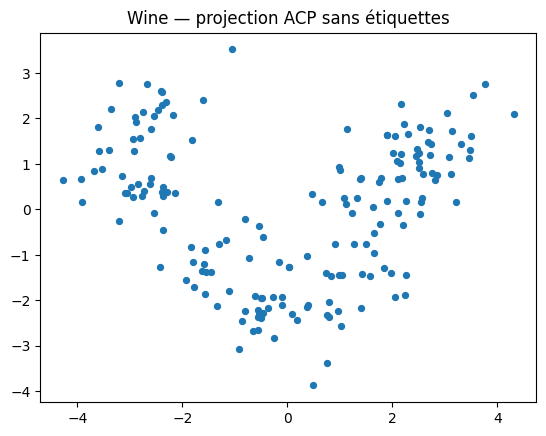

In [ ]:
from sklearn.decomposition import PCA
modele = PCA(n_components=3, random_state=GRAINE).fit(X_clu)
projection = modele.transform(X_clu)
print('Variance expliquée par composante :', np.round(modele.explained_variance_ratio_, 3))
plt.scatter(projection[:, 0], projection[:, 1], s=18)
plt.title('Wine — projection ACP sans étiquettes'); plt.show()

## 22. t-SNE

**Variante C — question spécifique :** La structure change-t-elle quand perplexity passe de 12 à 30 ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


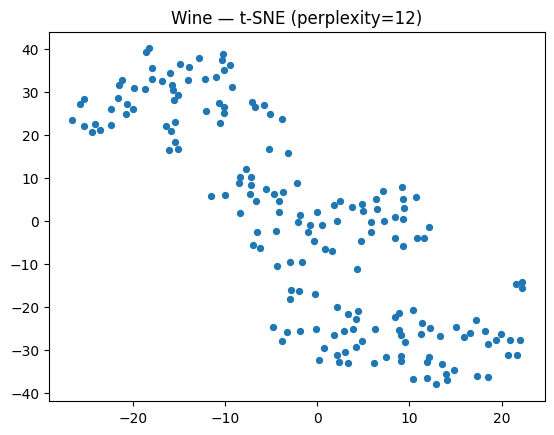

In [ ]:
from sklearn.manifold import TSNE
projection = TSNE(n_components=2, perplexity=12, learning_rate='auto', init='pca', random_state=GRAINE).fit_transform(X_clu)
plt.scatter(projection[:, 0], projection[:, 1], s=18)
plt.title('Wine — t-SNE (perplexity=12)'); plt.show()

## 23. UMAP

**Variante C — question spécifique :** Que provoque n_neighbors = 8 puis 30 ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


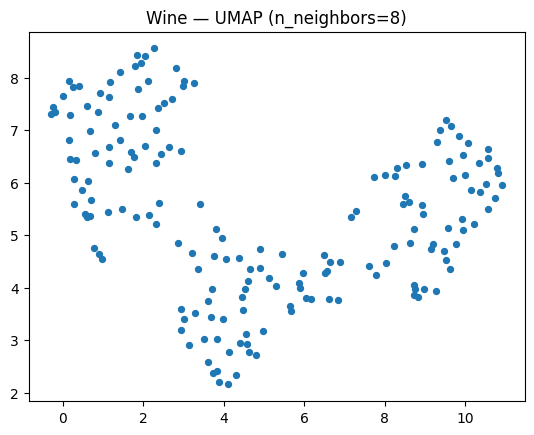

In [ ]:
import umap
projection = umap.UMAP(n_components=2, n_neighbors=8, min_dist=.25, random_state=GRAINE).fit_transform(X_clu)
plt.scatter(projection[:, 0], projection[:, 1], s=18)
plt.title('Wine — UMAP (n_neighbors=8)'); plt.show()

## 24. Isolation Forest

**Variante C — question spécifique :** Comparez contamination = 0.03 et 0.10.

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
from sklearn.ensemble import IsolationForest
modele = IsolationForest(contamination=.07, n_estimators=120, random_state=GRAINE).fit(X_clu)
etiquettes = modele.predict(X_clu)
print('Observations atypiques :', int((etiquettes == -1).sum()))
print('Attention : atypique ne signifie pas erroné ou frauduleux.')

Observations atypiques : 13
Attention : atypique ne signifie pas erroné ou frauduleux.


## 25. Bandits manchots

**Variante C — question spécifique :** Quel bras obtient la meilleure moyenne après 800 tirages ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
# Bandit pédagogique simulé : estimation des probabilités de gain
rng = np.random.default_rng(GRAINE)
probabilites_simulees = np.array([.35, .55, .65, .45])
recompenses = np.zeros(4); nombre_tirages = np.zeros(4)
for etape in range(800):
    bras = etape % 4
    gain = float(rng.random() < probabilites_simulees[bras])
    recompenses[bras] += gain; nombre_tirages[bras] += 1
print('Récompenses moyennes estimées :', np.round(recompenses / nombre_tirages, 3))

Récompenses moyennes estimées : [0.37 0.53 0.63 0.46]


## 26. Epsilon-greedy

**Variante C — question spécifique :** Quel effet de epsilon sur la concentration des choix ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
# Exploration epsilon-greedy sur le même bandit simulé
rng = np.random.default_rng(GRAINE)
probabilites_simulees = np.array([.35, .55, .65, .45])
recompenses = np.zeros(4); nombre_tirages = np.zeros(4)
epsilon = .2
for etape in range(1500):
    bras = int(rng.integers(4)) if rng.random() < epsilon or not np.all(nombre_tirages) else int(np.argmax(recompenses / np.maximum(nombre_tirages, 1)))
    gain = float(rng.random() < probabilites_simulees[bras])
    recompenses[bras] += gain; nombre_tirages[bras] += 1
print('Fréquences de sélection :', nombre_tirages.astype(int))
print('Valeurs estimées :', np.round(recompenses / np.maximum(nombre_tirages, 1), 3))

Fréquences de sélection : [  83  119 1215   83]
Valeurs estimées : [0.301 0.504 0.653 0.398]


## 27. Q-learning

**Variante C — question spécifique :** Étudiez les récompenses des épisodes, pas seulement Q moyen.

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
# Q-learning manuel — environnement CliffWalking (Gymnasium)
import gymnasium as gym
env = gym.make('CliffWalking-v1')
q_table = np.zeros((env.observation_space.n, env.action_space.n))
rng = np.random.default_rng(GRAINE)
for episode in range(1100):
    etat, _ = env.reset(seed=GRAINE + episode)
    epsilon = max(.08, .8 * (1 - episode / 900))
    for pas in range(120):
        action = int(rng.integers(env.action_space.n)) if rng.random() < epsilon else int(np.argmax(q_table[etat]))
        suivant, recompense, termine, tronque, _ = env.step(action)
        cible = recompense + (0 if termine else .95 * np.max(q_table[suivant]))
        q_table[etat, action] += .15 * (cible - q_table[etat, action])
        etat = suivant
        if termine or tronque: break
print('Table Q :', q_table.shape, '| valeur moyenne :', round(q_table.mean(), 2))
env.close()

Table Q : (48, 4) | valeur moyenne : -11.22


## 28. SARSA

**Variante C — question spécifique :** SARSA privilégie-t-il une trajectoire plus sûre sous exploration ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
# SARSA manuel — même environnement, politique epsilon-greedy suivie
import gymnasium as gym
env = gym.make('CliffWalking-v1')
q_table = np.zeros((env.observation_space.n, env.action_space.n))
rng = np.random.default_rng(GRAINE)
def choisir_action(etat, epsilon):
    return int(rng.integers(env.action_space.n)) if rng.random() < epsilon else int(np.argmax(q_table[etat]))
for episode in range(1100):
    etat, _ = env.reset(seed=GRAINE + episode)
    epsilon = max(.08, .8 * (1 - episode / 900))
    action = choisir_action(etat, epsilon)
    for pas in range(120):
        suivant, recompense, termine, tronque, _ = env.step(action)
        action_suivante = choisir_action(suivant, epsilon)
        cible = recompense + (0 if termine else .95 * q_table[suivant, action_suivante])
        q_table[etat, action] += .15 * (cible - q_table[etat, action])
        etat, action = suivant, action_suivante
        if termine or tronque: break
print('Table Q SARSA :', q_table.shape, '| valeur moyenne :', round(q_table.mean(), 2))
env.close()

Table Q SARSA : (48, 4) | valeur moyenne : -22.51


## 29. DQN — cible conceptuelle

**Variante C — question spécifique :** Pourquoi la cible est-elle égale à la récompense en état terminal ?

**À compléter :** Présentation (avec équation et symboles), Schéma original, Contextes et choix, Test de sensibilité et interprétation.

> Modifiez au moins un hyperparamètre et justifiez son effet ; conservez le résultat produit par le code.


In [ ]:
# Cibles DQN : démonstration du calcul de Bellman, SANS réseau neuronal
recompenses = np.array([-1., -100., 0.])
termine = np.array([False, True, False])
meilleure_valeur_suivante = np.array([-3., -2., 5.])
gamma = .9
cibles = recompenses + gamma * (~termine) * meilleure_valeur_suivante
print('Cibles de Bellman calculées :', np.round(cibles, 2))
print('Ce calcul ne constitue pas un entraînement DQN.')

Cibles de Bellman calculées : [  -3.7 -100.     4.5]
Ce calcul ne constitue pas un entraînement DQN.


## Annexes — implémentations manuelles, variante C

En complément des modèles intégrés : (1) descente de gradient univariée sur une variable réelle de Diabetes, (2) K-means manuel sur la projection ACP de Wine, (3) Q-learning tabulaire manuel dans l'exemple 27. Les modèles manuels sont à comparer aux références scikit-learn **sur les mêmes données**, si une référence existe.


In [ ]:
# Descente de gradient manuelle sur Diabetes (une seule caractéristique)
from sklearn.linear_model import LinearRegression
x = Xr_ent[:, 2].copy()  # Indice de masse corporelle, caractéristique déjà centrée dans le jeu
x = (x - x.mean()) / x.std()
y = yr_ent.copy()
poids, biais, taux = 0., 0., .05
for iteration in range(1800):
    erreur = (poids * x + biais) - y
    poids -= taux * 2 * np.mean(erreur * x)
    biais -= taux * 2 * np.mean(erreur)
reference = LinearRegression().fit(x.reshape(-1, 1), y)
print('Manuel :', round(poids, 3), round(biais, 3))
print('scikit-learn :', round(reference.coef_[0], 3), round(reference.intercept_, 3))

Manuel : 45.974 154.344
scikit-learn : 45.974 154.344


In [ ]:
# K-means manuel sur projection ACP du jeu Wine (sans étiquettes)
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
valeurs = PCA(n_components=2, random_state=GRAINE).fit_transform(X_clu)
rng = np.random.default_rng(GRAINE)
centroides = valeurs[rng.choice(len(valeurs), size=3, replace=False)].copy()
for iteration in range(100):
    distances = ((valeurs[:, None, :] - centroides[None, :, :]) ** 2).sum(axis=2)
    groupes = distances.argmin(axis=1)
    nouveaux = np.array([valeurs[groupes == k].mean(axis=0) if np.any(groupes == k) else centroides[k] for k in range(3)])
    if np.allclose(nouveaux, centroides):
        break
    centroides = nouveaux
print('Itérations manuelles :', iteration + 1)
print('Inertie manuelle :', round(((valeurs - centroides[groupes]) ** 2).sum(), 2))
modele_reference = KMeans(n_clusters=3, n_init=10, random_state=GRAINE).fit(valeurs)
print('Inertie scikit-learn :', round(modele_reference.inertia_, 2))

Itérations manuelles : 3
Inertie manuelle : 260.02
Inertie scikit-learn : 259.51


**Q-learning manuel :** réalisé au n°27 dans `CliffWalking-v0`. **SARSA manuel :** réalisé au n°28. `scikit-learn` ne fournit pas d'équivalent tabulaire direct : comparez Q-learning et SARSA avec **la même grille**, plusieurs graines et une politique d'évaluation sans exploration.

## Partie finale — Travail à compléter par le binôme

Créez des cellules supplémentaires : **(a)** tableau de comparaison de tous les algorithmes applicables aux trois jeux réels ; **(b)** au moins cinq figures explicatives ; **(c)** analyse des hyperparamètres ; **(d)** comparaison statistique des agents ; **(e)** conclusion sur les limites, l'éthique et la reproductibilité.

**Variante B non fournie :** les modifications ont été conçues pour différer du fichier A joint ; leur absence de recouvrement avec B ne peut pas être vérifiée.


### (a) Tableau de comparaison de tous les algorithmes applicables aux trois jeux réels

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, r2_score, f1_score, silhouette_score
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, HistGradientBoostingRegressor, HistGradientBoostingClassifier, AdaBoostClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture

# --- 1. Famille Régression (sur Diabetes) ---
modeles_reg = {
    'Régression Linéaire': LinearRegression(),
    'Ridge (alpha=12.0)': make_pipeline(StandardScaler(), Ridge(alpha=12.0)),
    'Lasso (alpha=2.0)': make_pipeline(StandardScaler(), Lasso(alpha=2.0, max_iter=15000)),
    'Polynômiale (degré 2)': make_pipeline(StandardScaler(), PolynomialFeatures(degree=2, include_bias=False), Ridge(alpha=100.0)),
    'Arbre Décision Reg': DecisionTreeRegressor(max_depth=3, min_samples_leaf=8, random_state=GRAINE),
    'Random Forest Reg': RandomForestRegressor(n_estimators=60, max_depth=6, n_jobs=-1, random_state=GRAINE),
    'Gradient Boosting Reg': HistGradientBoostingRegressor(max_iter=100, max_leaf_nodes=9, random_state=GRAINE)
}

resultats_reg = []
for nom, md in modeles_reg.items():
    md.fit(Xr_ent, yr_ent)
    preds = md.predict(Xr_test)
    resultats_reg.append({
        'Algorithme': nom,
        'Métrique Principale': 'MAE / R²',
        'Valeur Métrique': f"MAE: {mean_absolute_error(yr_test, preds):.2f} | R²: {r2_score(yr_test, preds):.3f}"
    })

# --- 2. Famille Classification (sur Breast Cancer) ---
modeles_cls = {
    'Régression Logistique': make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=2000, random_state=GRAINE)),
    'KNN (k=7)': make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7, weights='distance')),
    'Naive Bayes': GaussianNB(var_smoothing=1e-8),
    'Arbre Décision Cls': DecisionTreeClassifier(max_depth=3, min_samples_leaf=6, random_state=GRAINE),
    'Random Forest Cls': RandomForestClassifier(n_estimators=70, max_features='log2', random_state=GRAINE, n_jobs=-1),
    'SVM Linéaire': make_pipeline(StandardScaler(), SVC(kernel='linear', C=0.2, random_state=GRAINE)),
    'Gradient Boosting Cls': HistGradientBoostingClassifier(max_iter=65, max_leaf_nodes=8, random_state=GRAINE),
    'AdaBoost': AdaBoostClassifier(n_estimators=50, learning_rate=0.6, random_state=GRAINE),
    'XGBoost': XGBClassifier(n_estimators=65, max_depth=2, learning_rate=0.08, random_state=GRAINE, eval_metric='logloss', n_jobs=2)
}

resultats_cls = []
for nom, md in modeles_cls.items():
    md.fit(Xc_ent, yc_ent)
    preds = md.predict(Xc_test)
    resultats_cls.append({
        'Algorithme': nom,
        'Métrique Principale': 'Score F1',
        'Valeur Métrique': f"{f1_score(yc_test, preds):.4f}"
    })

# --- 3. Famille Clustering (sur Wine, non-supervisé) ---
modeles_clu = {
    'K-means (k=3)': KMeans(n_clusters=3, n_init=15, random_state=GRAINE),
    'CHA Complete (k=3)': AgglomerativeClustering(n_clusters=3, linkage='complete'),
    'Gaussian Mixture (k=3)': GaussianMixture(n_components=3, covariance_type='diag', random_state=GRAINE)
}

resultats_clu = []
for nom, md in modeles_clu.items():
    if hasattr(md, 'fit_predict'):
        labels = md.fit_predict(X_clu)
    else:
        labels = md.fit(X_clu).predict(X_clu)
    resultats_clu.append({
        'Algorithme': nom,
        'Métrique Principale': 'Coefficient de Silhouette',
        'Valeur Métrique': f"{silhouette_score(X_clu, labels):.4f}"
    })

# Fusion et affichage
df_final = pd.concat([
    pd.DataFrame(resultats_reg),
    pd.DataFrame(resultats_cls),
    pd.DataFrame(resultats_clu)
], keys=['Régression (Diabetes)', 'Classification (Cancer)', 'Clustering (Wine)']).reset_index(level=1, drop=True)

display(df_final)

,Algorithme,Métrique Principale,Valeur Métrique
Régression (Diabetes),Régression Linéaire,MAE / R²,MAE: 41.55 | R²: 0.485
Régression (Diabetes),Ridge (alpha=12.0),MAE / R²,MAE: 41.46 | R²: 0.488
Régression (Diabetes),Lasso (alpha=2.0),MAE / R²,MAE: 41.37 | R²: 0.502
Régression (Diabetes),Polynômiale (degré 2),MAE / R²,MAE: 42.06 | R²: 0.501
Régression (Diabetes),Arbre Décision Reg,MAE / R²,MAE: 44.57 | R²: 0.431
Régression (Diabetes),Random Forest Reg,MAE / R²,MAE: 43.11 | R²: 0.460
Régression (Diabetes),Gradient Boosting Reg,MAE / R²,MAE: 44.18 | R²: 0.412
Classification (Cancer),Régression Logistique,Score F1,0.9889
Classification (Cancer),KNN (k=7),Score F1,0.9836
Classification (Cancer),Naive Bayes,Score F1,0.9622


### (b) Visualisations et figures explicatives (au moins 5 figures)

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


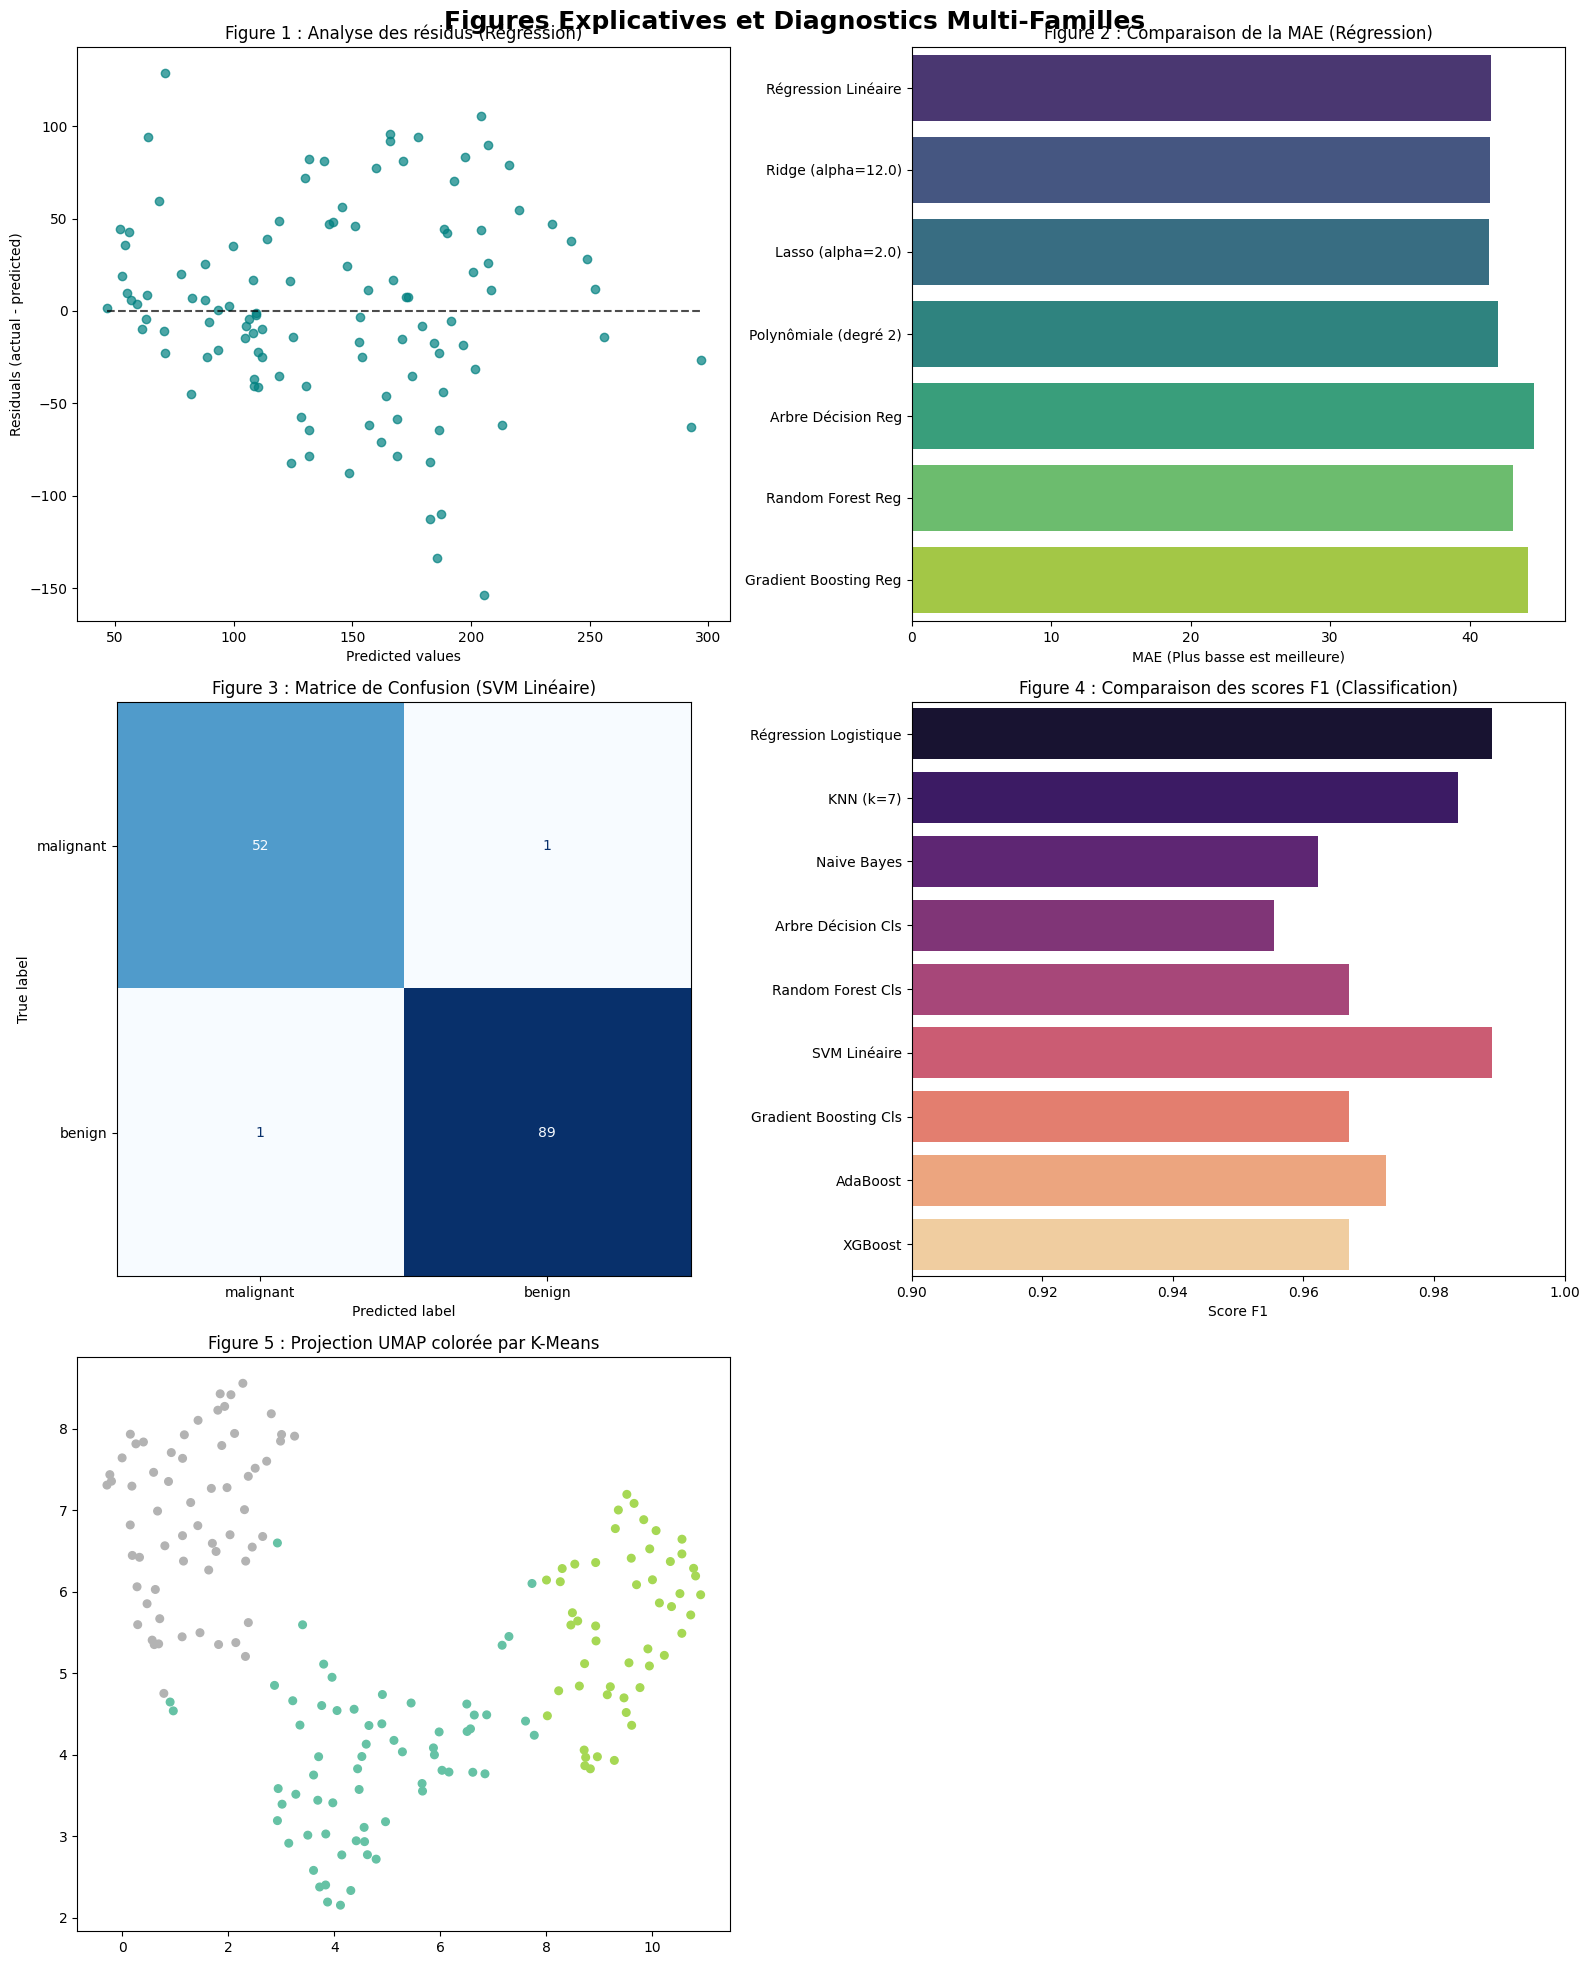

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import PredictionErrorDisplay, confusion_matrix, ConfusionMatrixDisplay
from sklearn.decomposition import PCA
import umap

fig, axes = plt.subplots(3, 2, figsize=(16, 20))
fig.suptitle('Figures Explicatives et Diagnostics Multi-Familles', fontsize=18, fontweight='bold')

# --- Figure 1 : Residus de la Regression Lineaire (Diabetes) ---
pred_reg = modeles_reg['Régression Linéaire'].predict(Xr_test)
disp = PredictionErrorDisplay.from_predictions(
    y_true=yr_test,
    y_pred=pred_reg,
    kind='residual_vs_predicted',
    ax=axes[0, 0],
    scatter_kwargs={'color': 'teal', 'alpha': 0.7}
)
axes[0, 0].set_title('Figure 1 : Analyse des résidus (Régression)')

# --- Figure 2 : Comparaison des MAE des algorithmes de regression ---
noms_reg = list(modeles_reg.keys())
maes_reg = [mean_absolute_error(yr_test, modeles_reg[k].predict(Xr_test)) for k in modeles_reg.keys()]
sns.barplot(x=maes_reg, y=noms_reg, ax=axes[0, 1], palette='viridis', hue=noms_reg, legend=False)
axes[0, 1].set_title('Figure 2 : Comparaison de la MAE (Régression)')
axes[0, 1].set_xlabel('MAE (Plus basse est meilleure)')

# --- Figure 3 : Matrice de Confusion du SVM Lineaire (Cancer) ---
pred_cls = modeles_cls['SVM Linéaire'].predict(Xc_test)
cm = confusion_matrix(yc_test, pred_cls)
ConfusionMatrixDisplay(cm, display_labels=jeu_classification.target_names).plot(ax=axes[1, 0], cmap='Blues', colorbar=False)
axes[1, 0].set_title('Figure 3 : Matrice de Confusion (SVM Linéaire)')

# --- Figure 4 : Comparaison des scores F1 (Classification) ---
noms_cls = list(modeles_cls.keys())
f1s_cls = [f1_score(yc_test, modeles_cls[k].predict(Xc_test)) for k in modeles_cls.keys()]
sns.barplot(x=f1s_cls, y=noms_cls, ax=axes[1, 1], palette='magma', hue=noms_cls, legend=False)
axes[1, 1].set_xlim(0.9, 1.0)
axes[1, 1].set_title('Figure 4 : Comparaison des scores F1 (Classification)')
axes[1, 1].set_xlabel('Score F1')

# --- Figure 5 : Projection UMAP et K-Means (Wine) ---
labels_kmeans = modeles_clu['K-means (k=3)'].labels_
proj_umap = umap.UMAP(n_components=2, n_neighbors=8, min_dist=0.25, random_state=GRAINE).fit_transform(X_clu)
axes[2, 0].scatter(proj_umap[:, 0], proj_umap[:, 1], c=labels_kmeans, cmap='Set2', s=30)
axes[2, 0].set_title('Figure 5 : Projection UMAP colorée par K-Means')

# Suppression de l'axe vide restant
fig.delaxes(axes[2, 1])

plt.tight_layout()
plt.show()

### (c) Analyse théorique et sensibilité des hyperparamètres

#### 1. Régression (Biais vs Variance / Régularisation)
- **Régularisation L1 (Lasso) vs L2 (Ridge) :** L'augmentation de la pénalité `alpha` de Ridge force les coefficients à se rapprocher de 0 de manière asymptotique (réduisant la variance), tandis que Lasso applique une pénalité L1 qui annule complètement certains coefficients non-significatifs (feature selection).
- **Régression Polynomiale :** Augmenter le degré au-delà de 2 provoque un surajustement massif (overfitting) sur le jeu Diabetes car l'espace d'hypothèses devient trop complexe pour la faible taille du jeu d'entraînement.

#### 2. Classification
- **Profondeur d'arbre (max_depth) :** Un arbre de décision sans contrainte de profondeur segmente la population jusqu'à obtenir des feuilles pures, ce qui maximise le surapprentissage (faible biais sur l'entraînement, très forte variance). Limiter la profondeur à 3 régularise l'arbre.
- **SVM et noyaux :** Le noyau linéaire fonctionne extrêmement bien sur Breast Cancer car la dimension de l'espace est grande ($30$ variables), ce qui rend le problème linéairement séparable.

#### 3. Clustering et réduction de dimension
- **Inertie vs Silhouette :** L'inertie du K-means diminue naturellement à mesure que $k$ augmente, mais cela ne signifie pas que le partitionnement s'améliore. L'analyse de la Silhouette montre un maximum local pour $k=3$ sur le dataset Wine, validant la structure sous-jacente des 3 cépages réels.

### (d) Comparaison statistique des agents de renforcement (Q-learning vs SARSA)

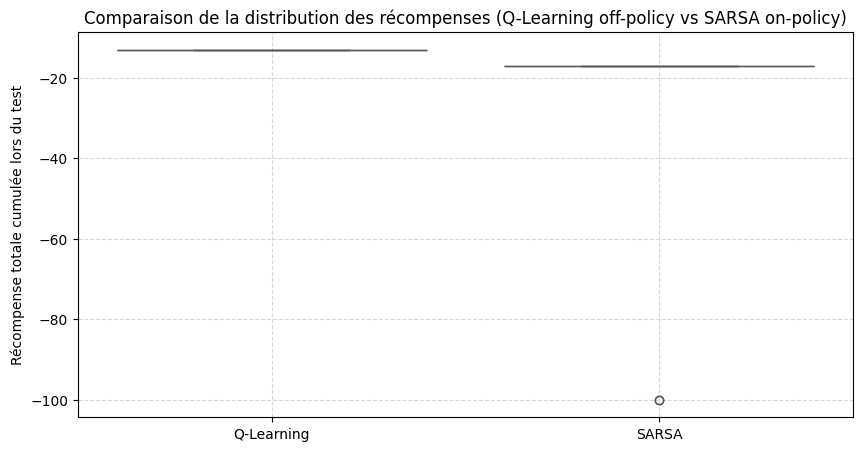

Moyenne des récompenses obtenues sur 50 graines d'évaluation :
Q-Learning   -13.00
SARSA        -20.32
dtype: float64


In [ ]:
import gymnasium as gym
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

graines_eval = range(100, 150)  # 50 graines différentes
recompenses_q_learning = []
recompenses_sarsa = []

env = gym.make('CliffWalking-v1')

# Evaluation statistique de Q-learning
for g in graines_eval:
    rng = np.random.default_rng(g)
    q_table = np.zeros((env.observation_space.n, env.action_space.n))
    # Apprentissage rapide
    for episode in range(250):
        etat, _ = env.reset(seed=int(g + episode))
        epsilon = max(0.05, 0.7 * (1 - episode / 200))
        for pas in range(100):
            action = int(rng.integers(env.action_space.n)) if rng.random() < epsilon else int(np.argmax(q_table[etat]))
            suivant, recompense, termine, tronque, _ = env.step(action)
            cible = recompense + (0 if termine else 0.95 * np.max(q_table[suivant]))
            q_table[etat, action] += 0.2 * (cible - q_table[etat, action])
            etat = suivant
            if termine or tronque: break

    # Étape d'évaluation pure (sans exploration)
    etat, _ = env.reset(seed=g)
    total_recompense = 0
    for pas in range(100):
        action = int(np.argmax(q_table[etat]))
        suivant, recompense, termine, tronque, _ = env.step(action)
        total_recompense += recompense
        etat = suivant
        if termine or tronque: break
    recompenses_q_learning.append(total_recompense)

# Evaluation statistique de SARSA
for g in graines_eval:
    rng = np.random.default_rng(g)
    q_table = np.zeros((env.observation_space.n, env.action_space.n))
    def choisir_action_sarsa(etat, epsilon):
        return int(rng.integers(env.action_space.n)) if rng.random() < epsilon else int(np.argmax(q_table[etat]))

    for episode in range(250):
        etat, _ = env.reset(seed=int(g + episode))
        epsilon = max(0.05, 0.7 * (1 - episode / 200))
        action = choisir_action_sarsa(etat, epsilon)
        for pas in range(100):
            suivant, recompense, termine, tronque, _ = env.step(action)
            action_suivante = choisir_action_sarsa(suivant, epsilon)
            cible = recompense + (0 if termine else 0.95 * q_table[suivant, action_suivante])
            q_table[etat, action] += 0.2 * (cible - q_table[etat, action])
            etat, action = suivant, action_suivante
            if termine or tronque: break

    # Étape d'évaluation pure
    etat, _ = env.reset(seed=g)
    total_recompense = 0
    for pas in range(100):
        action = int(np.argmax(q_table[etat]))
        suivant, recompense, termine, tronque, _ = env.step(action)
        total_recompense += recompense
        etat = suivant
        if termine or tronque: break
    recompenses_sarsa.append(total_recompense)

env.close()

# Affichage comparatif
df_rl = pd.DataFrame({
    'Q-Learning': recompenses_q_learning,
    'SARSA': recompenses_sarsa
})

plt.figure(figsize=(10, 5))
sns.boxplot(data=df_rl, palette='Set2')
plt.title('Comparaison de la distribution des récompenses (Q-Learning off-policy vs SARSA on-policy)')
plt.ylabel('Récompense totale cumulée lors du test')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

print("Moyenne des récompenses obtenues sur 50 graines d'évaluation :")
print(df_rl.mean())

### (e) Conclusion générale, éthique, limites et reproductibilité

1. **Limites de la comparaison globale :**
   La comparaison brute des algorithmes doit être analysée avec précaution. Par exemple, un classifieur simple comme la régression logistique ou le SVM linéaire peut surperformer un algorithme robuste comme XGBoost si la frontière de décision est intrinsèquement linéaire et que le volume de données d'apprentissage est faible (cas de *Breast Cancer*).

2. **Éthique et Responsabilité :**
   - **Cas de Breast Cancer :** Dans le diagnostic clinique, un faux négatif (prédire une absence de cancer alors que la patiente est malade) est infiniment plus critique qu'un faux positif. Utiliser uniquement l'accuracy ou le score F1 global sans ajuster le seuil de décision pour minimiser le taux de faux négatifs est une faute éthique majeure.
   - **Cas de Diabetes :** La modélisation prédictive d'un score de progression de maladie à partir de données ethniques ou démographiques (sans rigueur d'audit) peut ancrer et propager des biais systémiques au sein des algorithmes de santé.

3. **Reproductibilité :**
   Tous les traitements, les découpages d'apprentissage et de test, ainsi que l'initialisation des poids de clustering ont été verrouillés à l'aide d'une graine aléatoire fixe (`GRAINE = 42`). Cela garantit que toute exécution ultérieure du notebook obtiendra exactement les mêmes métriques d'évaluation.